# Gradient Boosting — classificação: guia passo a passo

**O que você vai aprender:** entender o problema, conhecer os dados, separar uma parte para conferir o resultado, preparar as colunas, treinar, comparar e interpretar.

Leia uma célula por vez. Antes de executar, tente responder: “o que entra aqui e o que sai?”. Os dados deste exemplo são didáticos; os números não são uma regra para todos os exercícios.

**Palavras úteis:** *atributos* são as colunas usadas para prever; *alvo* é a resposta que queremos descobrir; *treino* é a parte usada para aprender; *teste* é a parte guardada para conferir o resultado no fim.

## Antes do código: entendendo o caminho

**1. Qual é a pergunta?** Em regressão queremos prever um número, como gasto. Em classificação queremos escolher uma categoria, como “houve evento” ou “não houve”. Em agrupamento buscamos semelhanças sem uma resposta pronta. Diga isso em uma frase antes de escolher o algoritmo.

**2. O que são X e y?** `X` é uma tabela: linhas são casos, colunas são informações conhecidas no momento da previsão. `y` é a resposta de cada linha. Se uma coluna só aparece depois do resultado, ela não pode entrar em `X`: seria como olhar o gabarito.

**3. Por que guardar um teste?** O algoritmo pode se sair bem nos exemplos que já viu e falhar nos novos. Guardamos alguns casos e evitamos usá-los para escolher colunas, parâmetros ou modelos. A validação cruzada usa apenas o treino para comparar opções.

**4. O que faz o pipeline?** Ele guarda a receita completa: preencher dados ausentes, converter categorias, ajustar escalas quando necessário e treinar o modelo. Quando essa receita é testada em uma parte da validação, seus ajustes são aprendidos apenas na parte de treino daquela rodada.

**5. Como ler uma métrica?** Uma métrica resume um aspecto do erro. Ela não responde sozinha se o modelo é útil. Compare com o baseline, veja os tipos de erro e pense no custo real de errar. Uma diferença pequena entre médias de validação pode mudar em outra amostra.


## Fundamentos estatísticos para interpretar o resultado

**População e amostra.** População é o conjunto de casos sobre o qual gostaríamos de concluir. Amostra são as linhas disponíveis. Um teste em 140 pessoas descreve o desempenho nessas pessoas; é uma estimativa do que pode ocorrer em outras semelhantes, não uma garantia. Se o modo de coletar os dados favorece um grupo, uma divisão aleatória não corrige esse problema.

**Média, mediana e dispersão.** A média soma os valores e divide pela quantidade; é sensível a extremos. A mediana é o valor central depois de ordenar; resiste mais a extremos. O desvio padrão descreve o espalhamento em torno da média. Antes de tratar um valor extremo, investigue se é erro de registro ou um caso real importante.

**Correlação.** Resume associação linear entre duas variáveis. Perto de 1 indica que tendem a subir juntas; perto de -1, que uma tende a cair quando a outra sobe; perto de 0 não descarta relações curvas. Correlação não demonstra causa. Também pode mudar quando analisamos subgrupos.

**Incerteza e validação.** A média dos folds da validação cruzada resume vários treinos; o desvio entre folds mostra quanto os resultados variaram nessas divisões. Ele não é um intervalo de confiança. Ajustar muitos parâmetros e escolher o maior score pode produzir otimismo: por isso mantemos o teste separado até o final. Em dados temporais, a validação precisa respeitar a ordem do tempo.


## Estatística da classificação: leia antes dos gráficos

**Classes e prevalência.** Chamamos 1 de positivo, o evento que queremos encontrar. Prevalência é a fração de positivos. Se 5 de 100 casos são positivos, um modelo que diga sempre 0 acerta 95%, mas não encontra nenhum positivo. A acurácia isolada pode esconder isso.

**Matriz de confusão.** É uma tabela de respostas reais versus previstas. Verdadeiro positivo (VP): era 1 e o modelo disse 1. Falso positivo (FP): era 0 e disse 1, um alarme falso. Falso negativo (FN): era 1 e disse 0, um caso perdido. Verdadeiro negativo (VN): era 0 e disse 0. No gráfico do scikit-learn, linhas são reais e colunas são previstas; confira os rótulos dos eixos.

**Precisão e recall.** Precisão = VP/(VP+FP): entre os avisos positivos, quantos estavam certos? Recall ou sensibilidade = VP/(VP+FN): entre os positivos reais, quantos encontramos? Especificidade = VN/(VN+FP): entre os negativos reais, quantos descartamos? F1 combina precisão e recall em uma média harmônica; cai muito se um dos dois é baixo. Quando o denominador é zero, a métrica fica indefinida; `zero_division=0` apenas permite exibir o relatório, não prova bom desempenho.

**Limiar.** Um modelo pode produzir um escore para cada caso. Acima do limiar, dizemos 1; abaixo, 0. Reduzir o limiar costuma encontrar mais positivos e gerar mais falsos alarmes. Escolha o limiar conforme o custo dos dois erros usando somente treino e validação. O padrão do classificador não é necessariamente a melhor decisão prática.

**Curva ROC.** Em vários limiares, coloca no eixo horizontal a taxa de falsos positivos = FP/(FP+VN) e no vertical a taxa de verdadeiros positivos = recall. A AUC-ROC resume a capacidade de ordenar um positivo acima de um negativo: 0,5 é aproximadamente ordenação aleatória; 1 é ordenação perfeita nesta amostra. Mesmo uma AUC alta pode coexistir com muitos falsos alarmes quando positivos são raros.

**Curva precisão-recall.** Mostra a troca entre precisão e recall ao variar o limiar. Em classe rara, costuma evidenciar melhor o custo dos alarmes falsos. A linha de referência é aproximadamente a prevalência. Average Precision (AP) resume essa curva por uma convenção específica; não é a precisão em um único limiar. Compare modelos na mesma base e observe também o ponto de operação que faz sentido para o problema.


## Ideia do algoritmo, sem fórmula

O boosting monta árvores pequenas em sequência, cada uma tentando melhorar o conjunto atual.

Há duas escolhas importantes: o tamanho de cada passo (`learning_rate`) e a quantidade de passos (`n_estimators`). O melhor ajuste depende dos dados.

Não interprete um score alto no treino como vitória. Ele pode indicar que o modelo aprendeu detalhes específicos demais.

**Experimento mental:** se uma coluna passar a ter valores dez vezes maiores, o que pode mudar? Se o treino tiver poucos exemplos, o que pode acontecer? Depois de executar, compare suas respostas com os resultados.

## 1. Problema e critério de sucesso
Classificar inadimplência fictícia (1 = evento). Usamos **Average Precision (AP)** para avaliar o ranking em classes desbalanceadas. Não é precisão no limiar 0,5 nem a integral trapezoidal da curva PR. Quanto maior, melhor; a prevalência é uma referência útil. Precisão e recall no limiar padrão serão analisados ao final.

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

## Guia das funções e métodos usados neste notebook

As explicações também aparecem ao lado das células que usam cada função. Use este índice quando quiser rever uma ferramenta.

**`pd.DataFrame`** — Cria uma tabela com linhas e colunas. Aqui organiza as informações de entrada; não treina nada.

**`pd.Series`** — Cria uma coluna de valores. Aqui representa o alvo, isto é, as respostas conhecidas.

**`head`** — Mostra as primeiras linhas para conferir nomes de colunas, tipos aparentes e exemplos de valores.

**`info`** — Resume tipos de coluna e quantidade de valores presentes. Ajuda a encontrar colunas com ausências ou tipos inesperados.

**`describe`** — Calcula resumos como quantidade, média, desvio padrão, mínimo, quartis e máximo. Serve para procurar escalas e valores estranhos.

**`isna`** — Marca valores ausentes. Com `mean`, produz a fração ausente em cada coluna, porque verdadeiro conta como 1.

**`value_counts`** — Conta quantas vezes cada classe ou categoria aparece; com `normalize=True`, mostra proporções.

**`hist`** — Desenha histogramas para enxergar onde os valores se concentram e se há caudas ou extremos.

**`corr`** — Calcula correlações lineares entre colunas numéricas; associação não é causa e zero não exclui curvas.

**`train_test_split`** — Separa linhas em treino e teste. O treino serve para ajustar e comparar; o teste fica guardado para a avaliação final. `stratify=y` preserva aproximadamente as proporções das classes.

**`SimpleImputer`** — Aprende com o treino um valor para preencher ausências. `median` usa a mediana numérica; `most_frequent` usa a categoria mais comum.

**`StandardScaler`** — Aprende média e desvio padrão no treino e transforma as colunas numéricas para escalas comparáveis. É importante para distâncias, SVM e modelos com regularização.

**`OneHotEncoder`** — Converte categorias em colunas indicadoras. `handle_unknown="ignore"` evita erro se uma categoria nova aparecer; a nova categoria fica sem indicador ativo.

**`ColumnTransformer`** — Aplica uma preparação às colunas numéricas e outra às categóricas e depois junta o resultado.

**`Pipeline`** — Encadeia preparação e algoritmo em uma única receita. `fit` ajusta cada etapa com os dados permitidos; `predict` reaplica a mesma receita a linhas novas.

**`KFold`** — Define divisões repetidas do treino para estimar desempenho; cada parte vira validação uma vez.

**`StratifiedKFold`** — Faz as divisões repetidas mantendo aproximadamente a proporção das classes em cada parte.

**`GridSearchCV`** — Treina as combinações de parâmetros dadas, avalia cada uma nas divisões de validação e escolhe a maior média da métrica. `best_estimator_` é o pipeline vencedor reajustado em todo o treino; `best_score_` é a média de validação vencedora.

**`fit`** — Ajusta o modelo aos dados de treino. Em transformadores, aprende estatísticas como mediana e escala; em estimadores, aprende regras ou parâmetros.

**`predict`** — Gera uma resposta para cada linha. Em regressão, um número; em classificação, uma classe.

**`predict_proba`** — Retorna probabilidades estimadas por classe. Para classe binária, `[:, 1]` seleciona a coluna da classe 1; convém verificar `classes_` em bases adaptadas.

**`decision_function`** — Retorna um escore de posição em relação à fronteira de decisão. Ele ordena casos, mas não deve ser lido como probabilidade.

**`classification_report`** — Resume precisão, recall, F1 e suporte por classe. Suporte é a quantidade real de exemplos daquela classe.

**`ConfusionMatrixDisplay.from_predictions`** — Desenha a matriz de confusão a partir de valores reais e previstos; linhas são classes reais e colunas são previsões.

**`average_precision_score`** — Resume a curva precisão-recall variando o limiar. Maior é melhor; a prevalência serve como referência aproximada.

**`roc_auc_score`** — Resume a curva ROC. Mede qualidade de ordenação entre positivo e negativo, sem escolher um único limiar.

**`RocCurveDisplay.from_predictions`** — Desenha taxa de verdadeiros positivos contra taxa de falsos positivos em diferentes limiares.

**`PrecisionRecallDisplay.from_predictions`** — Desenha precisão contra recall em diferentes limiares, especialmente útil quando o evento positivo é raro.

**`mean_absolute_error`** — Calcula o tamanho médio dos erros sem cancelar positivos e negativos. Resultado na unidade do alvo; menor é melhor.

**`root_mean_squared_error`** — Calcula erro quadrático médio e depois tira a raiz. Dá mais peso aos erros grandes; menor é melhor.

**`r2_score`** — Compara o modelo com uma referência que prevê um valor constante. 1 é perfeito; 0 equivale à referência; pode ser negativo.

**`LinearRegression`** — Ajusta uma soma ponderada das colunas para prever número. É uma referência interpretável, mas precisa de atributos adicionais para capturar curvas.

**`Ridge`** — Regressão linear com penalização L2. `alpha` maior reduz mais os coeficientes e pode diminuir sensibilidade a ruído.

**`Lasso`** — Regressão linear com penalização L1. `alpha` maior pode zerar mais coeficientes e simplificar o modelo.

**`DecisionTreeRegressor`** — Árvore que divide casos por perguntas e prevê um número em cada folha. `max_depth` limita perguntas; `min_samples_leaf` evita folhas muito pequenas.

**`DecisionTreeClassifier`** — Árvore que divide casos por perguntas e prevê classe. Profundidade alta pode decorar o treino.

**`RandomForestRegressor`** — Média de várias árvores de regressão. `n_estimators` define quantas; mais árvores aumentam custo e costumam estabilizar o resultado.

**`RandomForestClassifier`** — Votação ou média de probabilidades de várias árvores. Pode ser mais estável que uma árvore isolada.

**`GradientBoostingRegressor`** — Adiciona árvores em sequência para reduzir erro de regressão. `learning_rate` controla o tamanho de cada correção e `n_estimators` a quantidade delas.

**`GradientBoostingClassifier`** — Adiciona árvores em sequência para melhorar classificação. Ajustes agressivos podem sobreajustar.

**`LogisticRegression`** — Aprende um escore linear e o converte em probabilidade estimada de classe. `C` menor significa regularização mais forte.

**`KNeighborsClassifier`** — Classifica pela votação dos vizinhos próximos. `n_neighbors` escolhe quantos consultar; escala das colunas afeta a distância.

**`SVC`** — Procura uma fronteira entre classes. Kernel RBF permite curvas; `C` penaliza erros e `gamma` controla a influência local.

**`GaussianNB`** — Combina evidências por probabilidade supondo distribuição gaussiana por classe e independência condicional entre atributos.

**`DummyClassifier`** — Baseline de classificação: usa uma regra simples, como a frequência das classes, sem aprender relação entre colunas e alvo.

**`DummyRegressor`** — Baseline de regressão: prevê um valor constante, como a média do treino.

In [1]:
# Bibliotecas: trazemos ferramentas prontas para tabelas, gráficos e modelos.
import pandas as pd

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [2]:
# Bibliotecas: trazemos ferramentas prontas para tabelas, gráficos e modelos.
import matplotlib.pyplot as plt

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [3]:
from IPython.display import display

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [4]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold, cross_val_score

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [5]:
from sklearn.compose import ColumnTransformer

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [6]:
from sklearn.pipeline import Pipeline

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [7]:
from sklearn.impute import SimpleImputer

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [8]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [9]:
from sklearn.dummy import DummyClassifier, DummyRegressor

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [10]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [11]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [12]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [13]:
from sklearn.neighbors import KNeighborsClassifier

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [14]:
from sklearn.svm import SVC

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [15]:
from sklearn.naive_bayes import GaussianNB

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [16]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, average_precision_score,
                             mean_absolute_error, root_mean_squared_error, r2_score)

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [17]:
# Usamos sempre o mesmo número para repetir os sorteios do exemplo.
SEMENTE = 42  # Torna a divisão e os modelos aleatórios reproduzíveis.

## 2. Dados e separação
Usamos uma base pequena e local para funcionar sem download. Nos seus exercícios, substitua esta célula pela leitura do CSV, escolha o alvo e exclua IDs e informações que só existem depois do evento. Se houver datas ou várias linhas por pessoa, use separação temporal ou por grupos em vez de sorteio.

### Lendo esta célula
`X` contém as informações e `y` contém a resposta. `train_test_split` separa linhas para treino e teste; `test_size=0.2` guarda 20%. `random_state` permite repetir a divisão. Em classificação, `stratify=y` procura manter proporções semelhantes das classes.

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [18]:
# Dados SINTÉTICOS: servem para aprender o fluxo, não representam uma empresa real.
# Cada linha representa um cliente fictício. random_state fixa o sorteio.
# As colunas abaixo são as informações disponíveis ANTES da resposta.
n = 700

**Funções e métodos desta célula**

`pd.DataFrame` cria uma tabela. Cada coluna recebe uma lista de valores e cada posição na lista forma uma linha. Aqui a tabela contém os atributos usados no modelo.

`pd.Series` cria uma coluna de valores. Aqui ela guarda as respostas reais, uma para cada linha de X.

In [19]:
# X é a tabela de informações que o modelo poderá consultar.
X = pd.DataFrame({
    "renda": pd.Series(range(n)).sample(frac=1, random_state=42).reset_index(drop=True) * 7 + 1000,
    "idade": pd.Series(range(n)).sample(frac=1, random_state=43).reset_index(drop=True) % 52 + 18,
    "divida": pd.Series(range(n)).sample(frac=1, random_state=44).reset_index(drop=True) * 27,
    "canal": (["loja", "site", "app"] * 234)[:n],
})

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [20]:
# Criamos a resposta com uma regra conhecida apenas para montar o exercício.
# Uma dívida alta e renda baixa aumentam a chance do evento.
# A comparação é booleana: True vira 1 e False vira 0.
y = ((X["divida"] > 11000) & (X["renda"] < 4200)).astype(int)

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [21]:
y.name = "inadimplente"

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [22]:
# Deixamos algumas informações faltando para praticar seu tratamento.
X.loc[::20, "renda"] = None

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [23]:
X.loc[::35, "canal"] = None

**Funções e métodos desta célula**

`train_test_split` divide as linhas em treino e teste. `test_size=0.2` guarda 20% para o teste. `random_state` repete a divisão. Em classificação, `stratify=y` procura preservar a proporção de cada classe nos dois conjuntos. A função devolve quatro objetos: X de treino, X de teste, y de treino e y de teste.

In [24]:
# Separamos ANTES da análise que orientará decisões. O teste fica reservado.
# Guardamos uma parte dos dados; ela será usada só na avaliação final.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, stratify=y)

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [25]:
assert set(X_treino.index).isdisjoint(X_teste.index)

**O que acontece nesta célula:** Mostramos o resultado em texto. Leia o número junto da métrica e da base usada; um valor isolado não diz se o modelo é útil.

In [26]:
print("Treino:", X_treino.shape, "Teste:", X_teste.shape)

Treino: (560, 4) Teste: (140, 4)


## 3. Análise exploratória do treino
Examine tipos, ausências, duplicatas, distribuição e relações plausíveis. Não remova outliers automaticamente: investigue unidades e erros de coleta. Duplicatas ou pessoas repetidas exigem uma estratégia de separação adequada.

<class 'pandas.DataFrame'>
Index: 560 entries, 223 to 443
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   renda   532 non-null    float64
 1   idade   560 non-null    int64  
 2   divida  560 non-null    int64  
 3   canal   548 non-null    str    
dtypes: float64(1), int64(2), str(1)
memory usage: 21.9 KB
Linhas duplicadas no treino: 0


,renda,idade,divida,canal
223,1161.0,60,7263,site
233,4997.0,19,7587,app
129,1287.0,36,8532,loja
671,1147.0,50,15768,app
467,2834.0,49,9963,app


,renda,idade,divida,canal
count,532.000000,560.000000,560.000000,548
unique,NaN,NaN,NaN,3
top,NaN,NaN,NaN,loja
freq,NaN,NaN,NaN,188
mean,3440.092105,43.251786,9319.339286,NaN
std,1424.673354,15.022553,5537.183995,NaN
min,1000.000000,18.000000,0.000000,NaN
25%,2235.500000,30.000000,4495.500000,NaN
50%,3401.000000,43.000000,9139.500000,NaN
75%,4669.750000,56.000000,14100.750000,NaN


renda     0.050000
idade     0.000000
divida    0.000000
canal     0.021429
Name: fracao_ausente, dtype: float64

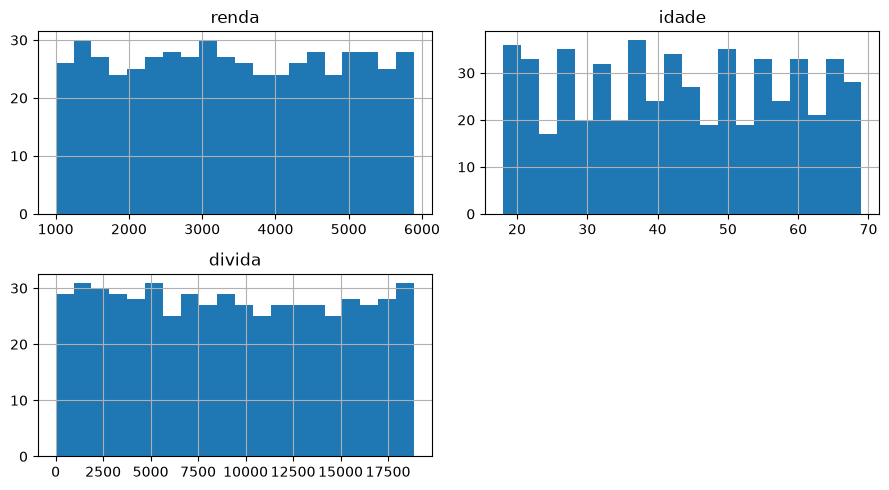

inadimplente
0    0.732143
1    0.267857
Name: proporcao, dtype: float64

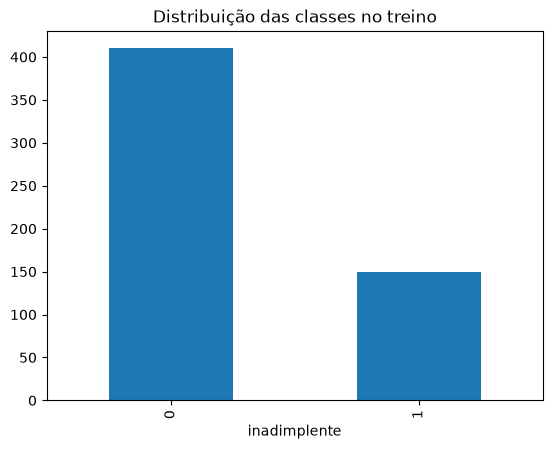

,renda,idade,divida,inadimplente
renda,1.000000,-0.014039,-0.002933,-0.395075
idade,-0.014039,1.000000,-0.029141,0.028541
divida,-0.002933,-0.029141,1.000000,0.613109
inadimplente,-0.395075,0.028541,0.613109,1.000000


In [27]:
display(X_treino.head())
X_treino.info()
display(X_treino.describe(include="all"))
display(X_treino.isna().mean().rename("fracao_ausente"))
print("Linhas duplicadas no treino:", X_treino.duplicated().sum())
X_treino.select_dtypes("number").hist(figsize=(9, 5), bins=20)
plt.tight_layout(); plt.show()
display(y_treino.value_counts(normalize=True).rename("proporcao"))
y_treino.value_counts().sort_index().plot.bar(title="Distribuição das classes no treino")
plt.show()
# Correlação é exploratória: não prova causa e não captura toda relação não linear.
display(X_treino.select_dtypes("number").join(y_treino).corr())

## 4. Preparação dentro do pipeline
Imputação preenche ausências; padronização coloca números em escala comparável; one-hot transforma categorias em indicadores. `handle_unknown="ignore"` permite prever categorias novas. Manter tudo no pipeline evita que a validação influencie as estatísticas aprendidas.

### Lendo esta célula
Primeiro listamos colunas numéricas e categóricas. `SimpleImputer` aprende um valor para preencher ausências. `StandardScaler` aprende média e escala; `OneHotEncoder` cria colunas 0/1 para categorias. `ColumnTransformer` une esses caminhos. Tudo será ajustado dentro do pipeline.

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [28]:
# Listas explícitas deixam claro quais colunas o exercício usa.
# Estas colunas contêm números.
numericas = ["renda", "idade", "divida"]

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [29]:
# Estas colunas contêm nomes de categorias.
categoricas = ["canal"]

**Funções e métodos desta célula**

`Pipeline` encadeia etapas. Neste guia, primeiro prepara as colunas e depois treina o algoritmo. Ao validar, cada divisão ajusta a preparação somente com seu próprio treino. `fit` aprende; `predict` usa essa receita já aprendida para gerar respostas novas.

`ColumnTransformer` encaminha colunas diferentes para preparações diferentes. Aqui números passam por imputação e escala; categorias passam por imputação e one-hot. Ao final, as colunas transformadas são reunidas para o modelo.

`SimpleImputer` aprende um valor de preenchimento apenas no treino. `strategy="median"` usa a mediana numérica; `most_frequent` usa a categoria mais comum. `transform` aplica o preenchimento aprendido a outras linhas.

`StandardScaler` aprende a média e o desvio padrão de cada coluna numérica no treino. Depois subtrai a média e divide pelo desvio padrão, permitindo comparar distâncias entre colunas em escalas diferentes.

`OneHotEncoder` transforma categorias em colunas indicadoras. Por exemplo, canal “app” vira uma coluna app igual a 1. `handle_unknown="ignore"` permite receber uma categoria nova sem falhar; `sparse_output=False` produz uma matriz densa.

In [30]:
# Cada ajuste de mediana, escala e categorias acontece somente no treino de cada fold.
# Cada tipo de coluna recebe o tratamento adequado.
preparo = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                       ("escala", StandardScaler())]), numericas),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categoricas)
])
# Árvores não precisam de padronização; mantemos uma preparação comum para facilitar a comparação.

## 5. Baseline, validação cruzada e busca
Baseline é um modelo simples que o algoritmo precisa justificar superar. Cada candidato usa os mesmos folds. A busca ajusta hiperparâmetros somente no treino, seleciona pela média de validação e reajusta o vencedor com todo o treino. A pontuação vencedora de validação tende a ser otimista por ter sido usada na seleção; a estimativa final vem do teste reservado. O desvio entre folds não é intervalo de confiança.

### Lendo esta célula
O dicionário `candidatos` dá um nome a cada modelo e lista valores que queremos experimentar. `GridSearchCV` treina combinações em várias divisões do treino. `best_score_` é a melhor média de validação. A tabela mostra também variação entre rodadas e resultado no próprio treino; diferença grande pode sugerir sobreajuste.

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [31]:
# Definimos como repetir a divisão do treino durante a comparação.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [32]:
# Esta é a régua usada para comparar os modelos.
metrica = "average_precision"

**O que acontece nesta célula:** Criamos as opções a comparar. A chave é o nome que aparecerá na tabela; o valor é o modelo com seus parâmetros. `range(2, 7)` testa 2, 3, 4, 5 e 6 grupos; o 7 não entra.

In [33]:
# Baseline participa da seleção: se vencer, não o descartamos para favorecer um modelo complexo.
# Cada entrada contém um modelo e as opções que queremos testar.
candidatos = {
    "Baseline": (DummyClassifier(strategy="prior"), {}),
    'Gradient Boosting — classificação': (GradientBoostingClassifier(random_state=SEMENTE), {'modelo__n_estimators': [60, 100], 'modelo__learning_rate': [0.05, 0.1]}),
}

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [34]:
# Guardaremos os resultados de cada candidato.
buscas = {}

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [35]:
linhas = []

**Funções e métodos desta célula**

`GridSearchCV` prepara uma busca de parâmetros. Recebe o pipeline, a grade de valores, a métrica em `scoring` e a divisão em `cv`. Ao chamar `fit`, treina cada combinação em cada divisão e escolhe a melhor média. `best_score_` é o resultado médio de validação; `best_estimator_` é o pipeline vencedor reajustado em todo o treino.

`Pipeline` encadeia etapas. Neste guia, primeiro prepara as colunas e depois treina o algoritmo. Ao validar, cada divisão ajusta a preparação somente com seu próprio treino. `fit` aprende; `predict` usa essa receita já aprendida para gerar respostas novas.

In [36]:
# Repetimos os mesmos passos para cada modelo.
for nome, (estimador, grade) in candidatos.items():
# A preparação e o modelo andam juntos em cada teste.
    pipeline = Pipeline([("preparo", preparo), ("modelo", estimador)])
# Testamos combinações de parâmetros usando só o treino.
    busca = GridSearchCV(pipeline, grade, scoring=metrica, cv=cv,
                         n_jobs=1, return_train_score=True, error_score="raise")
# Aqui o algoritmo aprende os padrões do treino.
    busca.fit(X_treino, y_treino)
    buscas[nome] = busca
    i = busca.best_index_
    linhas.append({"modelo": nome, "score_cv": busca.best_score_,
                   "desvio_cv": busca.cv_results_["std_test_score"][i],
                   "score_treino": busca.cv_results_["mean_train_score"][i],
                   "parametros": busca.best_params_})

**Funções e métodos desta célula**

`pd.DataFrame` cria uma tabela. Cada coluna recebe uma lista de valores e cada posição na lista forma uma linha. Aqui a tabela contém os atributos usados no modelo.

`sort_values` ordena as linhas pela coluna indicada; `ascending=False` coloca os maiores valores primeiro.

In [37]:
# Ordenamos pelo resultado médio da validação.
ranking = pd.DataFrame(linhas).sort_values("score_cv", ascending=False)

**O que acontece nesta célula:** Mostramos uma tabela para inspecionar o que foi calculado. Observe nomes das colunas, quantidade de linhas e valores inesperados.

In [38]:
display(ranking)

,modelo,score_cv,desvio_cv,score_treino,parametros
1,Gradient Boosting — classificação,0.984047,0.011820,1.000000,"{'modelo__learning_rate': 0.05, 'modelo__n_est..."
0,Baseline,0.267859,0.000678,0.267858,{}


**O que acontece nesta célula:** Escolhemos o primeiro colocado da validação, antes de consultar o teste. Assim a avaliação final continua independente da escolha.

In [39]:
# sklearn maximiza escores: em regressão, -MAE maior corresponde a MAE menor.
# Escolhemos antes de consultar o conjunto de teste.
melhor_nome = ranking.iloc[0]["modelo"]

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [40]:
melhor = buscas[melhor_nome].best_estimator_

**O que acontece nesta célula:** Mostramos o resultado em texto. Leia o número junto da métrica e da base usada; um valor isolado não diz se o modelo é útil.

In [41]:
print("Selecionado pela validação:", melhor_nome)

Selecionado pela validação: Gradient Boosting — classificação


## 6. Avaliação final — abrir o teste uma vez
O vencedor já foi definido. Esta célula mede generalização; não escolha outro algoritmo por observar o teste. Se mudar escolhas depois desta avaliação, será necessário outro conjunto independente. Diferença pequena entre candidatos pode não justificar complexidade adicional.

### Lendo esta célula
`predict` gera respostas para linhas que o modelo não viu. Compare `pred` com `y_teste`, que é o gabarito reservado. Em regressão, MAE é a média do tamanho dos erros; em classificação, a matriz de confusão separa acertos e os dois tipos de erro.

AP no teste: 0.9744
Prevalência no teste: 0.2714
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       102
           1       0.97      1.00      0.99        38

    accuracy                           0.99       140
   macro avg       0.99      1.00      0.99       140
weighted avg       0.99      0.99      0.99       140



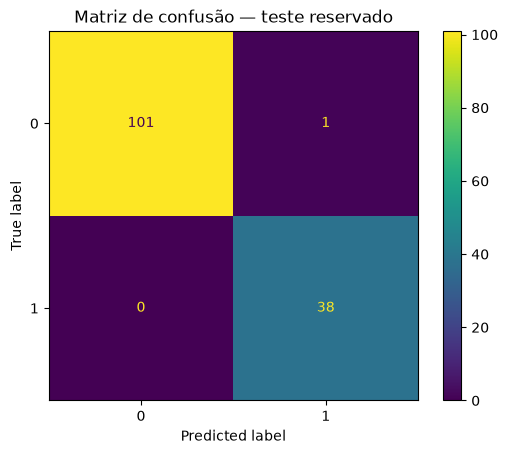

In [42]:
# Geramos respostas para os casos guardados.
pred = melhor.predict(X_teste)
# SVM fornece distância à fronteira; os demais candidatos fornecem probabilidades.
if hasattr(melhor, "predict_proba"):
    escore = melhor.predict_proba(X_teste)[:, 1]
else:
    escore = melhor.decision_function(X_teste)
print("AP no teste:", round(average_precision_score(y_teste, escore), 4))
print("Prevalência no teste:", round(y_teste.mean(), 4))
print(classification_report(y_teste, pred, zero_division=0))
# Gráfico: linhas são valores reais; colunas são previsões.
ConfusionMatrixDisplay.from_predictions(y_teste, pred)
plt.title("Matriz de confusão — teste reservado"); plt.show()

### Curvas de avaliação
A ROC mostra quanto recall ganhamos ao aceitar mais falsos positivos. A curva precisão-recall mostra quantos avisos positivos estão corretos conforme tentamos encontrar mais casos. Leia os eixos e a prevalência antes de comparar valores. Estas curvas descrevem o vencedor já escolhido; não servem para trocar de modelo depois de abrir o teste.

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [43]:
# Cada ponto das curvas representa um limiar diferente.
# Aqui usamos o teste apenas para DESCREVER o modelo já selecionado.
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score

**O que acontece nesta célula:** Construímos um gráfico dos resultados. Confira os eixos, a legenda e se os pontos representam treino ou teste antes de interpretar.

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

**Funções e métodos desta célula**

`RocCurveDisplay.from_predictions` desenha a curva ROC a partir de rótulos reais e escores. O eixo horizontal é a taxa de falsos positivos; o vertical, o recall.

In [45]:
# ROC: cada ponto corresponde a um limiar diferente.
RocCurveDisplay.from_predictions(y_teste, escore, ax=axes[0])

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [46]:
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Referência aleatória")

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [47]:
axes[0].set_title("ROC: encontrar positivos × alarmes falsos")

**Funções e métodos desta célula**

`PrecisionRecallDisplay.from_predictions` desenha precisão e recall para diferentes limiares. Ajuda a visualizar o custo de tentar encontrar mais positivos.

In [48]:
# Outra visão dos limiares: precisão contra recall.
PrecisionRecallDisplay.from_predictions(y_teste, escore, ax=axes[1])

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [49]:
axes[1].axhline(y_teste.mean(), linestyle="--", color="gray", label="Prevalência")

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [50]:
axes[1].set_title("Precisão × recall")

**O que acontece nesta célula:** Construímos um gráfico dos resultados. Confira os eixos, a legenda e se os pontos representam treino ou teste antes de interpretar.

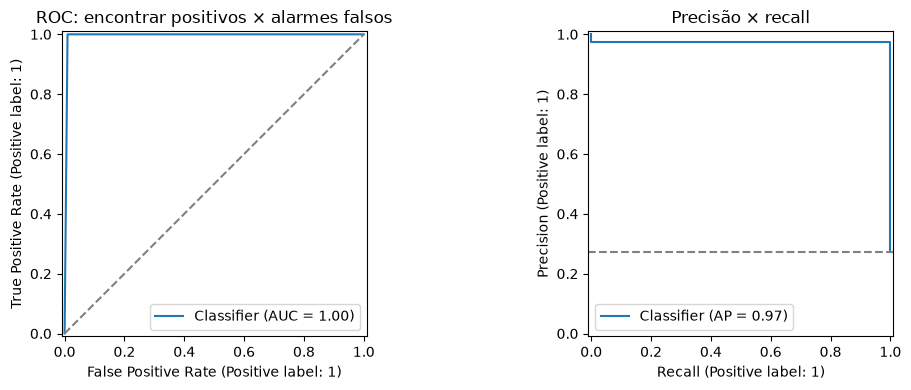

In [51]:
plt.tight_layout(); plt.show()

**Funções e métodos desta célula**

`roc_auc_score` resume o gráfico ROC em um número. Mede a ordenação de positivos e negativos ao variar o limiar; não escolhe o limiar de uso.

In [52]:
print("AUC-ROC no teste:", round(roc_auc_score(y_teste, escore), 4))

AUC-ROC no teste: 0.9951


**Funções e métodos desta célula**

`average_precision_score` recebe respostas binárias e escores, varia o limiar e resume precisão versus recall. Maior é melhor; prevalência é uma referência aproximada.

In [53]:
print("AP no teste:", round(average_precision_score(y_teste, escore), 4))

AP no teste: 0.9744


## 7. Nova previsão e reutilização
Envie as mesmas colunas originais: o pipeline repete a preparação aprendida. Uma previsão para linha fictícia demonstra a API, não comprova qualidade. Você pode salvar o pipeline inteiro com joblib; só carregue arquivos de origem confiável.

In [54]:
# Criamos uma linha nova para demonstrar uma previsão.
novo = pd.DataFrame([{"renda": 4200, "idade": 32, "divida": 8000, "canal": "app"}])
print("Previsão para exemplo fictício:", melhor.predict(novo))
# Opcional, após avaliar e registrar o experimento:
# import joblib
# joblib.dump(melhor, "pipeline.joblib")
# carregado = joblib.load("pipeline.joblib")

Previsão para exemplo fictício: [0]


## 8. Como interpretar e adaptar
Constrói um conjunto sequencial de árvores, corrigindo a perda atual. Pode capturar interações; árvores demais ou aprendizado agressivo podem sobreajustar.

Observe falsos negativos e falsos positivos separadamente. AP alto não garante bom recall no limiar padrão. Ajuste de limiar, calibração e reamostragem precisam ocorrer apenas com treino/validação; SMOTE deve ficar dentro de um pipeline do imbalanced-learn, nunca antes da divisão.

**Exercícios:** substitua o CSV; justifique cada atributo; escolha a métrica pelo problema; amplie a grade no treino; compare com baseline; escreva uma conclusão citando score de validação, resultado final, limitações e próximo experimento. Não existe um melhor algoritmo universal.

**Modelo de conclusão:** “Entre os candidatos e grades testados, ___ obteve a melhor média de validação em ___. No teste reservado, obteve ___. A limitação principal é ___. Para o uso proposto, o erro é/não é aceitável porque ___.”